In [5]:
%pip install opencv-python pandas seaborn matplotlib gdown scikit-learn


Note: you may need to restart the kernel to use updated packages.



# 01 - Exploration des donnees

## Objectif
Explorer le dataset d'IRM cérébrales avant l'entraînement.



In [7]:
import os
import gdown
import zipfile
from pathlib import Path

FILE_ID = '1PP09vNLPEsiFXFyKu4_8mC-bFJbxfflC' 

url = f'hhttps://drive.google.com/uc?id={FILE_ID}'
zip_output = 'tumors_dataset.zip'
extract_dir = 'extract/'


try:
    if not os.path.exists(zip_output):
        gdown.download(url, zip_output, quiet=False)

    with zipfile.ZipFile(zip_output, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)

    data_path = Path(extract_dir)
    if (data_path / 'Data').exists():
        data_path = data_path / 'Data'
    elif (data_path / 'tumors' / 'Data').exists():
        data_path = data_path / 'tumors' / 'Data'

    print(f"Targeting data directory at: {data_path}")


except Exception as e:
    print(f"\n An error occurred: {e}")
    print("Please check your file ID, folder nesting inside the ZIP, or Drive permissions.")

Targeting data directory at: extract/Data


In [8]:
import glob
import cv2
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [9]:
extention_images = {".jpeg", ".jpg", ".bmp", ".png"}
DATA_DIREC = data_path
files_images = []
classes = ["notumor","pituitary","meningioma","glioma"]

for class_name in classes:
    class_path = DATA_DIREC/class_name

    files = [
        file for file in class_path.rglob("*")
        if file.is_file()
        and file.suffix.lower() in extention_images
    ]

    files_images.extend(
        (file, class_name) for file in files
    )

print(" nombre total d'images :", len(files_images))

 nombre total d'images : 7023


In [10]:
# creation un dataframe des images :

df_images = pd.DataFrame(files_images,columns=["path", "label"])

print(df_images.head())

print("\nNombre d'images par classe :")
print(df_images["label"].value_counts())

                                    path    label
0  extract/Data/notumor/Te-noTr_0000.jpg  notumor
1  extract/Data/notumor/Te-noTr_0001.jpg  notumor
2  extract/Data/notumor/Te-noTr_0002.jpg  notumor
3  extract/Data/notumor/Te-noTr_0003.jpg  notumor
4  extract/Data/notumor/Te-noTr_0004.jpg  notumor

Nombre d'images par classe :
label
notumor       2000
pituitary     1757
meningioma    1645
glioma        1621
Name: count, dtype: int64


In [11]:
# Redimensionner les images à une taille fixe (ex. 224×224) à l'aide de la bibliothèque OpenCV:

images = []
labels = []

for file_path, label in files_images:
    try:
        image = cv2.imread(str(file_path))

        if image is None:
            print("-- image illisible :", file_path)
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        image = cv2.resize(image, (224, 224))

        images.append(image)
        labels.append(label)

    except Exception as error:
        print("Erreur :", file_path, error)
        continue

print("Images chargees :", len(images))
print("Labels charges :", len(labels))

Images chargees : 7023
Labels charges : 7023


In [12]:
# Convertir les listes d'images et d'étiquettes en tableaux NumPy pour les rendre exploitables par le modèle:

X = np.array(images, dtype=np.uint8)
y = np.array(labels)

print("X shape :", X.shape)
print("y shape :", y.shape)
print("Classes :", np.unique(y))

X shape : (7023, 224, 224, 3)
y shape : (7023,)
Classes : ['glioma' 'meningioma' 'notumor' 'pituitary']


glioma : 1621 images
meningioma : 1645 images
notumor : 2000 images
pituitary : 1757 images


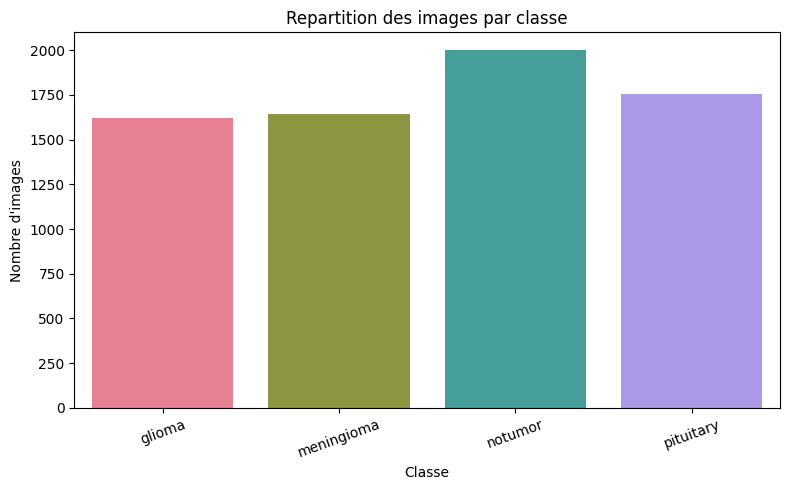

In [13]:
# Conmter le nombre d'images par classe
classes, counts = np.unique(y, return_counts=True)

# Afficher les résultats
for classe, nombre in zip(classes, counts):
    print(f"{classe} : {nombre} images")

plt.figure(figsize=(8, 5))

sns.barplot(x=classes, y=counts, hue=classes, palette="husl",legend=False)

plt.title("Repartition des images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

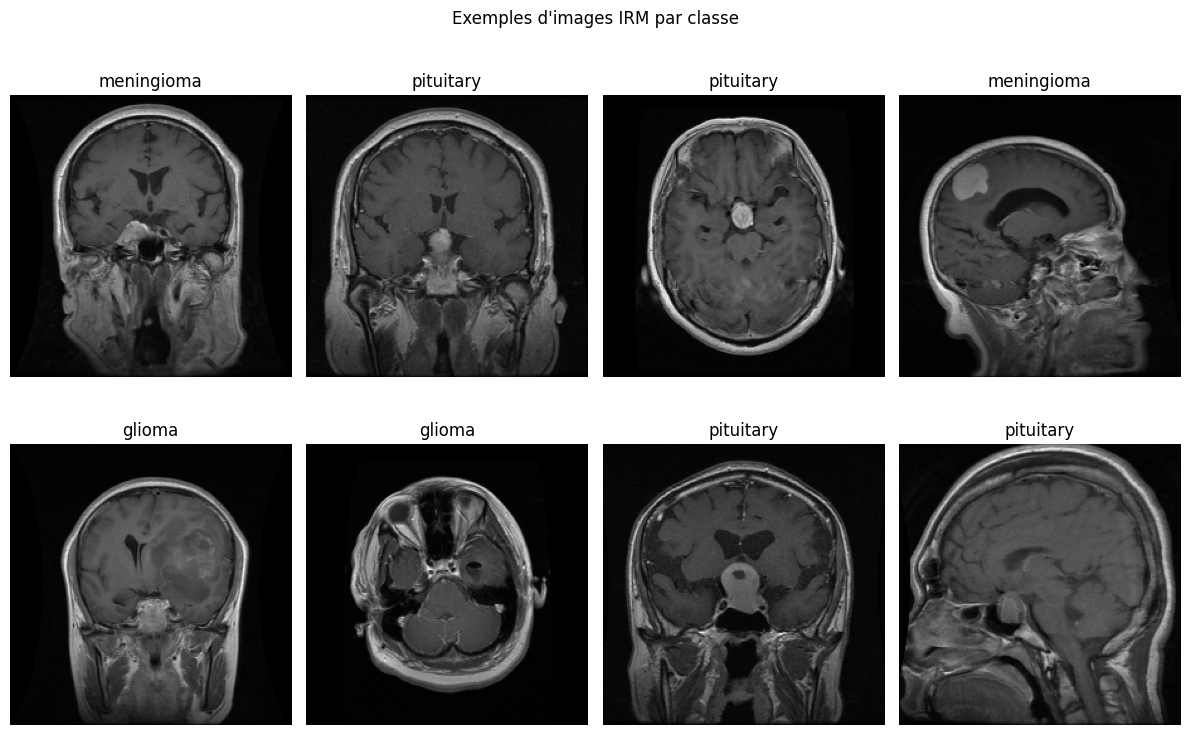

In [14]:
# Afficher 8 images aléatoires

np.random.seed(42)

nombre_images = min(8, len(X))
indices = np.random.choice(len(X), size=nombre_images, replace=False)

plt.figure(figsize=(12, 8))

for position, index in enumerate(indices):
    plt.subplot(2, 4, position + 1)
    plt.imshow(X[index])
    plt.title(y[index])
    plt.axis("off")

plt.suptitle("Exemples d'images IRM par classe")
plt.tight_layout()
plt.show()
